In [1]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import load_csv_data
from implementations import logistic_regression
from implementations import compute_logistic_loss
from implementations import reg_logistic_regression

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("dataset")

In [3]:
def preprocess(x_train, x_test, max_nan=0.95):
    n_unique = np.array([len(np.unique(col[~np.isnan(col)])) for col in x_train.T])
    nan_frac = np.mean(np.isnan(x_train), axis=0)
    keep = (n_unique > 1) & (nan_frac <= max_nan)
    x_tr = x_train[:, keep]
    x_te = x_test[:, keep]

    mean = np.nanmean(x_tr, axis=0)
    std = np.nanstd(x_tr, axis=0)
    x_tr = (x_tr - mean) / std
    x_te = (x_te - mean) / std

    x_tr = np.nan_to_num(x_tr, nan=0.0)
    x_te = np.nan_to_num(x_te, nan=0.0)

    x_tr = np.c_[np.ones(len(x_tr)), x_tr]
    x_te = np.c_[np.ones(len(x_te)), x_te]

    return x_tr, x_te, keep

In [4]:
tx_tr, tx_te, keep = preprocess(x_train, x_test)
print(tx_tr.shape, tx_te.shape)
print("any NaN left:", np.isnan(tx_tr).any(), np.isnan(tx_te).any())

(328135, 250) (109379, 250)
any NaN left: False False


In [5]:
threshold = int(np.ceil(0.85 * tx_tr.shape[0]))

np.random.seed(0) 
indices = np.random.permutation(tx_tr.shape[0])

tx_tr = tx_tr[indices]
tx, tv = tx_tr[:threshold], tx_tr[threshold:]


y_train = (y_train == 1) * 1
y_train[indices]
y_t, y_v = y_train[:threshold], y_train[threshold:]

gamma=0.3, max_iters=100: val accuracy=0.8908
gamma=0.3, max_iters=200: val accuracy=0.9037
gamma=0.3, max_iters=500: val accuracy=0.9099
gamma=0.3, max_iters=1000: val accuracy=0.9107
gamma=0.3, max_iters=2000: val accuracy=0.9108
gamma=0.5, max_iters=100: val accuracy=0.9016
gamma=0.5, max_iters=200: val accuracy=0.9083
gamma=0.5, max_iters=500: val accuracy=0.9106
gamma=0.5, max_iters=1000: val accuracy=0.9108
gamma=0.5, max_iters=2000: val accuracy=0.9108
gamma=0.7, max_iters=100: val accuracy=0.9052
gamma=0.7, max_iters=200: val accuracy=0.9097
gamma=0.7, max_iters=500: val accuracy=0.9108
gamma=0.7, max_iters=1000: val accuracy=0.9108
gamma=0.7, max_iters=2000: val accuracy=0.9108
gamma=0.9, max_iters=100: val accuracy=0.9073
gamma=0.9, max_iters=200: val accuracy=0.9101
gamma=0.9, max_iters=500: val accuracy=0.9108
gamma=0.9, max_iters=1000: val accuracy=0.9108
gamma=0.9, max_iters=2000: val accuracy=0.9108
gamma=1.1, max_iters=100: val accuracy=0.9087
gamma=1.1, max_iters=200: 

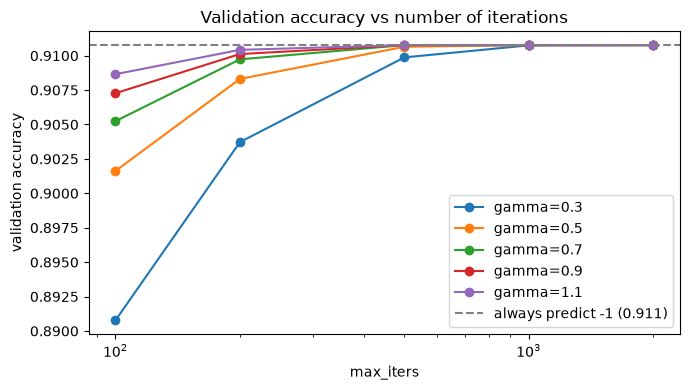

In [6]:
gammas = [0.3, 0.5, 0.7, 0.9, 1.1]
max_iters_list = [100, 200, 500, 1000, 2000]

np.random.seed(0) 
w_initial = np.random.rand(tx.shape[1])

def accuracy(yv, tv, w):
    pred = (tv @ w >= 0).astype(float)   # same as sigmoid(tx @ w) >= 0.5
    return np.mean(pred == yv)

# Baseline: always predict the majority class (-1)
baseline = 1 - np.mean(y_v)

plt.figure(figsize=(7, 4))

for gamma in gammas:
    val_accs = []
    for max_iters in max_iters_list:
        w, tr_loss = logistic_regression(y_t, tx, w_initial, max_iters, gamma)
        acc = accuracy(y_v, tv, w)
        val_accs.append(acc)
        print(f"gamma={gamma}, max_iters={max_iters}: val accuracy={acc:.4f}")
    plt.semilogx(max_iters_list, val_accs, "o-", label=f"gamma={gamma}")

plt.axhline(baseline, color="gray", linestyle="--", label=f"always predict -1 ({baseline:.3f})")
plt.xlabel("max_iters")
plt.ylabel("validation accuracy")
plt.title("Validation accuracy vs number of iterations")
plt.legend()
plt.tight_layout()
plt.savefig("2_val_accuracy_vs_max_iters.png", dpi=300, bbox_inches="tight")
plt.show()

lambda=1e-06, max_iters=100: val accuracy=0.9087
lambda=1e-06, max_iters=200: val accuracy=0.9104
lambda=1e-06, max_iters=500: val accuracy=0.9108
lambda=1e-06, max_iters=1000: val accuracy=0.9108
lambda=1e-06, max_iters=2000: val accuracy=0.9108
lambda=1e-05, max_iters=100: val accuracy=0.9087
lambda=1e-05, max_iters=200: val accuracy=0.9104
lambda=1e-05, max_iters=500: val accuracy=0.9108
lambda=1e-05, max_iters=1000: val accuracy=0.9108
lambda=1e-05, max_iters=2000: val accuracy=0.9108
lambda=0.0001, max_iters=100: val accuracy=0.9087
lambda=0.0001, max_iters=200: val accuracy=0.9105
lambda=0.0001, max_iters=500: val accuracy=0.9108
lambda=0.0001, max_iters=1000: val accuracy=0.9108
lambda=0.0001, max_iters=2000: val accuracy=0.9108
lambda=0.001, max_iters=100: val accuracy=0.9095
lambda=0.001, max_iters=200: val accuracy=0.9107
lambda=0.001, max_iters=500: val accuracy=0.9108
lambda=0.001, max_iters=1000: val accuracy=0.9108
lambda=0.001, max_iters=2000: val accuracy=0.9108
lambda=

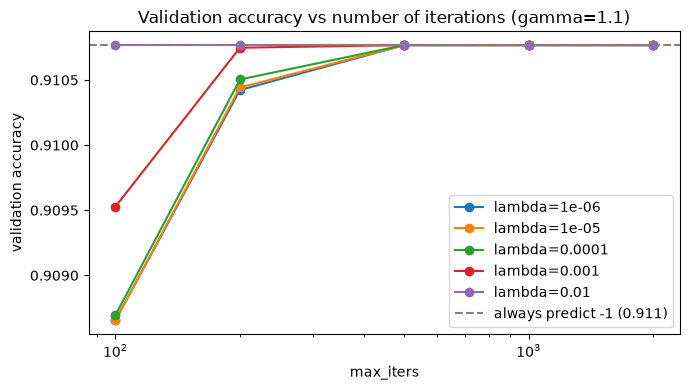

In [7]:
gamma = 1.1                                 
lambdas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]
max_iters_list = [100, 200, 500, 1000, 2000]

np.random.seed(0) 
w_initial = np.random.rand(tx.shape[1])

def accuracy(yv, tv, w):
    pred = (tv @ w >= 0).astype(float)   
    return np.mean(pred == yv)


baseline = 1 - np.mean(y_v)

plt.figure(figsize=(7, 4))

for lambda_ in lambdas:
    val_accs = []
    for max_iters in max_iters_list:
        w, tr_loss = reg_logistic_regression(y_t, tx, lambda_, w_initial, max_iters, gamma)
        acc = accuracy(y_v, tv, w)
        val_accs.append(acc)
        print(f"lambda={lambda_}, max_iters={max_iters}: val accuracy={acc:.4f}")
    plt.semilogx(max_iters_list, val_accs, "o-", label=f"lambda={lambda_}")

plt.axhline(baseline, color="gray", linestyle="--", label=f"always predict -1 ({baseline:.3f})")
plt.xlabel("max_iters")
plt.ylabel("validation accuracy")
plt.title(f"Validation accuracy vs number of iterations (gamma={gamma})")
plt.legend()
plt.tight_layout()
plt.savefig("2_val_accuracy_reg_vs_max_iters.png", dpi=300, bbox_inches="tight")
plt.show()